In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import time
import warnings
warnings.filterwarnings('ignore')

def MIC_data_reader(filename='MIC_processing.csv'):
    data = pd.read_csv(filename)
    X = data.drop(['LET_IS'],axis = 1)
    y = data['LET_IS']
    return X, y

In [2]:
# from imblearn.over_sampling import SMOTE
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
import lightgbm as lgb
from sklearn.metrics import confusion_matrix,accuracy_score,roc_curve,classification_report,f1_score,accuracy_score
from sklearn.linear_model import LogisticRegression

# define the characteristic function
def classification_kpi(G,S):
    """_summary_

    Args:
        G (nx.Graph): _description_
        S (list): list of nodes (list of columns)
    """
    cols = list(S)
    if len(cols) == 0:
        return 0
    else:
        X_train, X_test, y_train, y_test = train_test_split(X[cols], y, test_size=0.2, random_state=42)
        model = LogisticRegression()

        model.fit(X_train, y_train)

        y_pred = model.predict(X_test)  # 预测类别

        # accuracy = accuracy_score(y_test, y_pred)
        f1 = f1_score(y_test, y_pred)

        return f1

In [3]:
# import shapG and necessary libraries
import networkx as nx
import shapG.shapley as shapley
import shapG.plot as shapGplot
from shapG.utils import corr_generator, create_minimal_edge_graph
import time
s = time.time()

In [4]:
# explain the model
X, y = MIC_data_reader('MIC_processing.csv')
W = corr_generator(X)
A, W_new = create_minimal_edge_graph(W, version='v3')
G = nx.Graph(A)
shapley_value = shapley.shapG(G, m=3, f=classification_kpi, approximate_by_ratio=False)

100%|█████████████████████████████████████████| 111/111 [02:40<00:00,  1.45s/it]


In [5]:
e = time.time()
e-s

163.34974312782288

In [6]:
sorted_data = sorted(shapley_value.items(), key=lambda x: x[1], reverse=True)
sorted_data[:30]

[('K_SH_POST', 3.2331263046073504),
 ('D_AD_ORIT', 1.3367443381567714),
 ('RAZRIV', 1.0368177238163394),
 ('S_AD_ORIT', 0.7457689006790316),
 ('ZSN_A', 0.7146590659972323),
 ('NA_R_1_n', 0.21017710196989778),
 ('n_p_ecg_p_12', 0.18196663071596836),
 ('NITR_S', 0.1368493704864996),
 ('R_AB_3_n', 0.13280910384861508),
 ('ANT_CA_S_n', 0.12811111392990618),
 ('ASP_S_n', 0.12712449462560338),
 ('ritm_ecg_p_01', 0.11335492187056981),
 ('AGE', 0.07404865506569713),
 ('nr_04', 0.06415909618703963),
 ('SEX', 0.058158541578766425),
 ('NA_R_3_n', 0.048004711665592635),
 ('ritm_ecg_p_02', 0.044410708691775685),
 ('n_p_ecg_p_06', 0.04295923304202641),
 ('TIME_B_S', 0.04143408185759673),
 ('ritm_ecg_p_07', 0.03974568960410052),
 ('zab_leg_03', 0.03553317443053573),
 ('GB', 0.03539534039086403),
 ('L_BLOOD', 0.03443925727796499),
 ('O_L_POST', 0.03199869352550274),
 ('IM_PG_P', 0.02675780467540456),
 ('n_r_ecg_p_05', 0.02657939183638598),
 ('STENOK_AN', 0.022618397072099613),
 ('R_AB_1_n', 0.02171878

In [7]:
sorted_data

[('K_SH_POST', 3.2331263046073504),
 ('D_AD_ORIT', 1.3367443381567714),
 ('RAZRIV', 1.0368177238163394),
 ('S_AD_ORIT', 0.7457689006790316),
 ('ZSN_A', 0.7146590659972323),
 ('NA_R_1_n', 0.21017710196989778),
 ('n_p_ecg_p_12', 0.18196663071596836),
 ('NITR_S', 0.1368493704864996),
 ('R_AB_3_n', 0.13280910384861508),
 ('ANT_CA_S_n', 0.12811111392990618),
 ('ASP_S_n', 0.12712449462560338),
 ('ritm_ecg_p_01', 0.11335492187056981),
 ('AGE', 0.07404865506569713),
 ('nr_04', 0.06415909618703963),
 ('SEX', 0.058158541578766425),
 ('NA_R_3_n', 0.048004711665592635),
 ('ritm_ecg_p_02', 0.044410708691775685),
 ('n_p_ecg_p_06', 0.04295923304202641),
 ('TIME_B_S', 0.04143408185759673),
 ('ritm_ecg_p_07', 0.03974568960410052),
 ('zab_leg_03', 0.03553317443053573),
 ('GB', 0.03539534039086403),
 ('L_BLOOD', 0.03443925727796499),
 ('O_L_POST', 0.03199869352550274),
 ('IM_PG_P', 0.02675780467540456),
 ('n_r_ecg_p_05', 0.02657939183638598),
 ('STENOK_AN', 0.022618397072099613),
 ('R_AB_1_n', 0.02171878

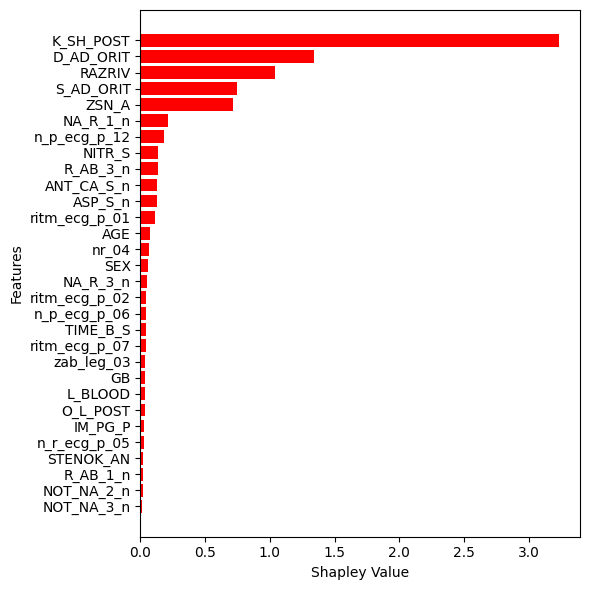

In [2]:
import matplotlib.pyplot as plt
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
import numpy as np

# 提取特征名称和权重（按权重从大到小排序）
data = [('K_SH_POST', 3.2331263046073504),
 ('D_AD_ORIT', 1.3367443381567714),
 ('RAZRIV', 1.0368177238163394),
 ('S_AD_ORIT', 0.7457689006790316),
 ('ZSN_A', 0.7146590659972323),
 ('NA_R_1_n', 0.21017710196989778),
 ('n_p_ecg_p_12', 0.18196663071596836),
 ('NITR_S', 0.1368493704864996),
 ('R_AB_3_n', 0.13280910384861508),
 ('ANT_CA_S_n', 0.12811111392990618),
 ('ASP_S_n', 0.12712449462560338),
 ('ritm_ecg_p_01', 0.11335492187056981),
 ('AGE', 0.07404865506569713),
 ('nr_04', 0.06415909618703963),
 ('SEX', 0.058158541578766425),
 ('NA_R_3_n', 0.048004711665592635),
 ('ritm_ecg_p_02', 0.044410708691775685),
 ('n_p_ecg_p_06', 0.04295923304202641),
 ('TIME_B_S', 0.04143408185759673),
 ('ritm_ecg_p_07', 0.03974568960410052),
 ('zab_leg_03', 0.03553317443053573),
 ('GB', 0.03539534039086403),
 ('L_BLOOD', 0.03443925727796499),
 ('O_L_POST', 0.03199869352550274),
 ('IM_PG_P', 0.02675780467540456),
 ('n_r_ecg_p_05', 0.02657939183638598),
 ('STENOK_AN', 0.022618397072099613),
 ('R_AB_1_n', 0.02171878658126707),
 ('NOT_NA_2_n', 0.018240657383286892),
 ('NOT_NA_3_n', 0.01527931955815603)]
labels, values = zip(*data)

plt.figure(figsize=(6, 6))

# 使用Matplotlib的barh()函数绘制条形图
plt.barh(labels, values, color='r')
plt.gca().invert_yaxis()

plt.xlabel('Shapley Value')
plt.ylabel('Features')

# 使用tight_layout来调整图表以适应指定的图形大小
plt.tight_layout()

# 保存图像，确保DPI设置为300，并包括标签和边距
plt.savefig('original_shapG_MIC_LogisticRegression.eps', format='eps', dpi=300, bbox_inches='tight')

plt.show()


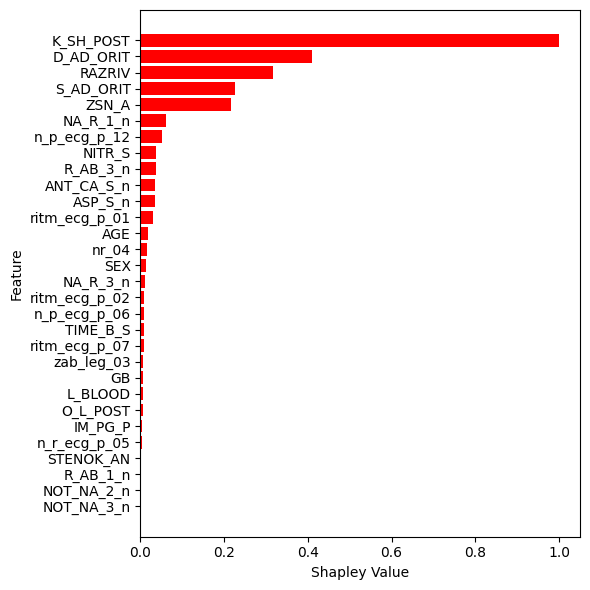

In [5]:
import matplotlib.pyplot as plt
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


# 提取特征名称和权重（按权重从大到小排序）
data = [('K_SH_POST', 3.2331263046073504),
 ('D_AD_ORIT', 1.3367443381567714),
 ('RAZRIV', 1.0368177238163394),
 ('S_AD_ORIT', 0.7457689006790316),
 ('ZSN_A', 0.7146590659972323),
 ('NA_R_1_n', 0.21017710196989778),
 ('n_p_ecg_p_12', 0.18196663071596836),
 ('NITR_S', 0.1368493704864996),
 ('R_AB_3_n', 0.13280910384861508),
 ('ANT_CA_S_n', 0.12811111392990618),
 ('ASP_S_n', 0.12712449462560338),
 ('ritm_ecg_p_01', 0.11335492187056981),
 ('AGE', 0.07404865506569713),
 ('nr_04', 0.06415909618703963),
 ('SEX', 0.058158541578766425),
 ('NA_R_3_n', 0.048004711665592635),
 ('ritm_ecg_p_02', 0.044410708691775685),
 ('n_p_ecg_p_06', 0.04295923304202641),
 ('TIME_B_S', 0.04143408185759673),
 ('ritm_ecg_p_07', 0.03974568960410052),
 ('zab_leg_03', 0.03553317443053573),
 ('GB', 0.03539534039086403),
 ('L_BLOOD', 0.03443925727796499),
 ('O_L_POST', 0.03199869352550274),
 ('IM_PG_P', 0.02675780467540456),
 ('n_r_ecg_p_05', 0.02657939183638598),
 ('STENOK_AN', 0.022618397072099613),
 ('R_AB_1_n', 0.02171878658126707),
 ('NOT_NA_2_n', 0.018240657383286892),
 ('NOT_NA_3_n', 0.01527931955815603)]
labels, values = zip(*data)

# 将权重转换为numpy数组
values = np.array(values).reshape(-1, 1)

# 使用MinMaxScaler进行归一化
scaler = MinMaxScaler()
normalized_values = scaler.fit_transform(values).flatten()

# 绘制条形图
plt.figure(figsize=(6, 6))

# 使用Matplotlib的barh()函数绘制条形图
plt.barh(labels, normalized_values, color='r')

plt.xlabel('Shapley Value')
plt.ylabel('Feature')

# 使用tight_layout来调整图表以适应指定的图形大小
plt.tight_layout()
plt.gca().invert_yaxis()

# 保存图像，确保DPI设置为300，并包括标签和边距
# plt.savefig('shapG_diabets_lgb_normalized.eps', format='eps', dpi=300, bbox_inches='tight')

# plt.show()
# 保存图像，确保DPI设置为300，并包括标签和边距
plt.savefig('original_shapG_MIC_LogisticRegression_normalized.eps', format='eps', dpi=300, bbox_inches='tight')

plt.show()
